# Quadruped robot object detection

This notebook prepares and evaluates a two-class object-detection dataset from **COCO 2017** and **Stanford Dogs**.

## Design rules

- Original source images are assigned to train, validation, or test **before** any derived view is created.
- COCO `train2017` is training-only. COCO `val2017` is deterministically divided between validation and test.
- Stanford Dogs is independently divided 80/10/10 by source image and every XML `<object>` is retained.
- Full scenes and all available human/dog boxes are preserved. Training-only partial views retain context and transform every intersecting box.
- Native image dimensions and aspect ratios are preserved. Ultralytics letterboxes them to the fixed **320 x 320** model input with rectangular batching disabled. Stretching source images to 320 x 320 would distort object shape and is intentionally avoided.
- Validation and test contain no generated augmentations and no source group used for training.
- Runs and checkpoints are explicit; the notebook never discovers or resumes the latest run automatically.


In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
from ultralytics import YOLO

from quadruped_pipeline import (
    CLASS_NAMES,
    audit_dataset,
    benchmark_batch_one,
    best_f1_confidence,
    build_dataset,
    clear_ultralytics_label_caches,
    dataset_identity,
    draw_labelled_image,
    environment_report,
    evaluate_coco_pretrained_baseline,
    format_yolo_cli,
    finalize_run_binding,
    load_source_records,
    negative_false_positive_rate,
    prepare_run_binding,
    read_manifest,
    resolve_image_list,
    run_binding_path,
    sample_preview_rows,
    screen_stanford_person_candidates,
    select_loaded_sources,
    summarize_ap_metrics,
    summarize_metrics,
    training_arguments,
    validate_without_metric_logging,
    verify_checkpoint_binding,
)

if sys.version_info[:2] != (3, 11):
    raise RuntimeError("Use Python 3.11 with the pinned requirements for this notebook.")

ENVIRONMENT = environment_report()
print(json.dumps(ENVIRONMENT, indent=2))


{
  "python": "3.11.13",
  "platform": "macOS-26.5.2-arm64-arm-64bit",
  "opencv": "4.11.0",
  "numpy": "1.26.0",
  "torch": "2.12.0",
  "ultralytics": "8.4.53",
  "mps_available": "True",
  "cuda_available": "False"
}


## Configuration

The selected limits keep the experiment practical on a 16 GB M2 Pro while retaining every COCO dog/mixed scene, dog diversity from Stanford, multi-object scenes, and 20% negatives. The source manifest and configuration fingerprint make reuse explicit and prevent a stale dataset from being accepted silently.


In [2]:
REPO_ROOT = Path.cwd().resolve()
if not (REPO_ROOT / "quadruped_pipeline.py").exists():
    raise RuntimeError("Run this notebook from the quadrupedvision repository root.")

DATASET_ROOT = REPO_ROOT / "dataset_v2"
COCO_ROOT = REPO_ROOT / "data/coco2017"
STANFORD_ROOT = REPO_ROOT / "data/stanford-dogs-dataset"
STANFORD_SCREEN_CACHE = STANFORD_ROOT / "person_screen_yolov8n.json"

CONFIG = {
    "seed": 42,
    "image_size": 320,
    "dataset_root": str(DATASET_ROOT),
    "yaml_dir": str(REPO_ROOT),
    "coco_root": str(COCO_ROOT),
    "stanford_root": str(STANFORD_ROOT),
    "min_box_pixels": 4.0,
    "min_partial_visibility": 0.25,
    "partial_view_fraction": 0.25,
    "negative_fraction": 0.20,
    "max_coco_person_only": {"train": 4000, "val": 1000, "test": 1000},
    "max_stanford": {"train": 8000, "val": 1000, "test": 1000},
    "stanford_person_screen_model": str(REPO_ROOT / "yolov8n.pt"),
    "stanford_person_screen_confidence": 0.20,
    "stanford_person_screen_size": 640,
}

BUILD_DATASET = False
REBUILD_DATASET = False
RUN_FULL_AUDIT = False
RUN_STANFORD_PERSON_SCREEN = True
REBUILD_STANFORD_SCREEN = False
# BUILD_DATASET = True
# REBUILD_DATASET = False
# RUN_FULL_AUDIT = True
# RUN_STANFORD_PERSON_SCREEN = True
# REBUILD_STANFORD_SCREEN = False

print("Source images remain at native size; YOLO input size:", CONFIG["image_size"])
print("Dataset output:", DATASET_ROOT)


Source images remain at native size; YOLO input size: 320
Dataset output: /Users/romansannikov/Projects/quadrupedvision/dataset_v2


## Source inventory, grouping, and selection

Stanford Dogs annotates dogs but not people. To avoid knowingly treating visible people as background, a COCO-pretrained YOLOv8n model screens Stanford images for person candidates. Candidate images are excluded rather than pseudo-labelled. Screening uses 640 pixels only to reduce missed small people during data cleaning; training and deployment remain fixed at 320. The screening cache is fingerprinted and should be manually inspected for a final thesis release because automatic screening cannot guarantee that every person is found.


In [3]:
if BUILD_DATASET:
    COCO_RECORDS, STANFORD_RECORDS, SOURCE_LOAD_REPORT = load_source_records(CONFIG)
    print(json.dumps(SOURCE_LOAD_REPORT, indent=2, sort_keys=True))

    if RUN_STANFORD_PERSON_SCREEN:
        screen_device = "mps" if torch.backends.mps.is_available() else "cpu"
        STANFORD_EXCLUSIONS = screen_stanford_person_candidates(
            records=STANFORD_RECORDS,
            cache_path=STANFORD_SCREEN_CACHE,
            model_path=CONFIG["stanford_person_screen_model"],
            device=screen_device,
            confidence=CONFIG["stanford_person_screen_confidence"],
            image_size=CONFIG["stanford_person_screen_size"],
            batch=16,
            rebuild=REBUILD_STANFORD_SCREEN,
        )
    else:
        STANFORD_EXCLUSIONS = set()
        print("WARNING: Stanford person screening is disabled; visible people may be unlabelled.")

    SOURCE_SELECTION, SELECTION_REPORT = select_loaded_sources(
        COCO_RECORDS,
        STANFORD_RECORDS,
        CONFIG,
        stanford_exclusions=STANFORD_EXCLUSIONS,
    )
    SOURCE_REPORT = {**SOURCE_LOAD_REPORT, **SELECTION_REPORT}
    print(json.dumps(SELECTION_REPORT, indent=2, sort_keys=True))
else:
    COCO_RECORDS, STANFORD_RECORDS = [], []
    STANFORD_EXCLUSIONS = set()
    SOURCE_SELECTION, SOURCE_REPORT = {}, {}
    print("BUILD_DATASET=False: skipping source loading, screening, and selection.")


BUILD_DATASET=False: skipping source loading, screening, and selection.


In [4]:
REVIEW_STANFORD_SCREEN = False

if BUILD_DATASET and REVIEW_STANFORD_SCREEN and STANFORD_EXCLUSIONS:
    screen_data = json.loads(STANFORD_SCREEN_CACHE.read_text())
    confidence_by_id = {
        candidate["source_id"]: candidate["max_confidence"]
        for candidate in screen_data["candidates"]
    }
    record_by_id = {record.source_id: record for record in STANFORD_RECORDS}
    candidate_ids = sorted(STANFORD_EXCLUSIONS)
    rng = np.random.default_rng(CONFIG["seed"])
    selected_ids = rng.choice(candidate_ids, size=min(12, len(candidate_ids)), replace=False)
    figure, axes = plt.subplots(3, 4, figsize=(16, 12))
    for axis, source_id in zip(axes.flat, selected_ids):
        record = record_by_id[str(source_id)]
        axis.imshow(plt.imread(record.image_path))
        axis.set_title(f"person confidence {confidence_by_id[str(source_id)]:.2f}")
        axis.axis("off")
    for axis in axes.flat[len(selected_ids):]:
        axis.axis("off")
    plt.tight_layout()


## Build the versioned dataset

Full images are copied so Ultralytics cannot mutate the public source files while repairing malformed JPEG end markers. Missing JPEG end markers are repaired during materialization, before the artifact audit. Training-only partial views are square scene crops but are not resized. Photometric augmentation is left to Ultralytics at training time instead of creating hundreds of thousands of offline duplicates.


In [5]:
if BUILD_DATASET:
    DATASET_METADATA = build_dataset(
        config=CONFIG,
        selected=SOURCE_SELECTION,
        source_report=SOURCE_REPORT,
        rebuild=REBUILD_DATASET,
        build_if_missing=True,
    )
else:
    metadata_path = DATASET_ROOT / "dataset_metadata.json"
    if not metadata_path.exists():
        raise FileNotFoundError("No existing dataset metadata. Set BUILD_DATASET=True first.")
    DATASET_METADATA = json.loads(metadata_path.read_text())
    print("BUILD_DATASET=False: loaded the existing dataset metadata.")

print(json.dumps(DATASET_METADATA["list_counts"], indent=2, sort_keys=True))
print("Dataset fingerprint:", DATASET_METADATA["fingerprint"])

BUILD_DATASET=False: loaded the existing dataset metadata.
{
  "test": 2611,
  "test_coco": 1618,
  "test_stanford": 993,
  "train": 24303,
  "train_coco": 14331,
  "train_stanford": 9972,
  "val": 2583,
  "val_coco": 1590,
  "val_stanford": 993
}
Dataset fingerprint: 20ecc1fa787521d2c15edafd3ca501e0e98126a3187584804e2b6ba01095dad2


## Full dataset audit

This scans every selected image and label. It verifies decoding, dimensions, class IDs, normalized coordinates, pairing, source-group separation, path separation, exact content hashes, perceptual hashes, and whether derived samples appear outside training.


In [6]:
if RUN_FULL_AUDIT:
    AUDIT_REPORT = audit_dataset(DATASET_ROOT, write_report=True)
else:
    audit_path = DATASET_ROOT / "audit_report.json"
    if not audit_path.exists():
        raise FileNotFoundError("Run the full audit at least once.")
    AUDIT_REPORT = json.loads(audit_path.read_text())

print(json.dumps(AUDIT_REPORT, indent=2, sort_keys=True))


{
  "artifact_digest": "381198c9e2aa6f939e6d880dfbb8e0a1406e1e95d40768d53ac9a4e711f7d9a6",
  "exact_cross_split_groups": 0,
  "identical_dhash_cross_split_groups": 0,
  "identical_dhash_examples": {},
  "near_duplicate_cross_split_groups": 0,
  "path_overlap": {
    "train_test": [],
    "train_val": [],
    "val_test": []
  },
  "source_overlap": {
    "train_test": [],
    "train_val": [],
    "val_test": []
  },
  "splits": {
    "test": {
      "class_0_objects": 3161,
      "class_1_objects": 1165,
      "full_frame_box_ratio": 0.0009246417013407304,
      "full_frame_boxes": 4,
      "images": 2611,
      "negative_images": 523,
      "objects": 4326,
      "source_coco": 1618,
      "source_stanford": 993
    },
    "train": {
      "class_0_objects": 20493,
      "class_1_objects": 16975,
      "full_frame_box_ratio": 0.0019483292409522793,
      "full_frame_boxes": 73,
      "images": 24303,
      "negative_images": 4061,
      "objects": 37468,
      "source_coco": 14331,
   

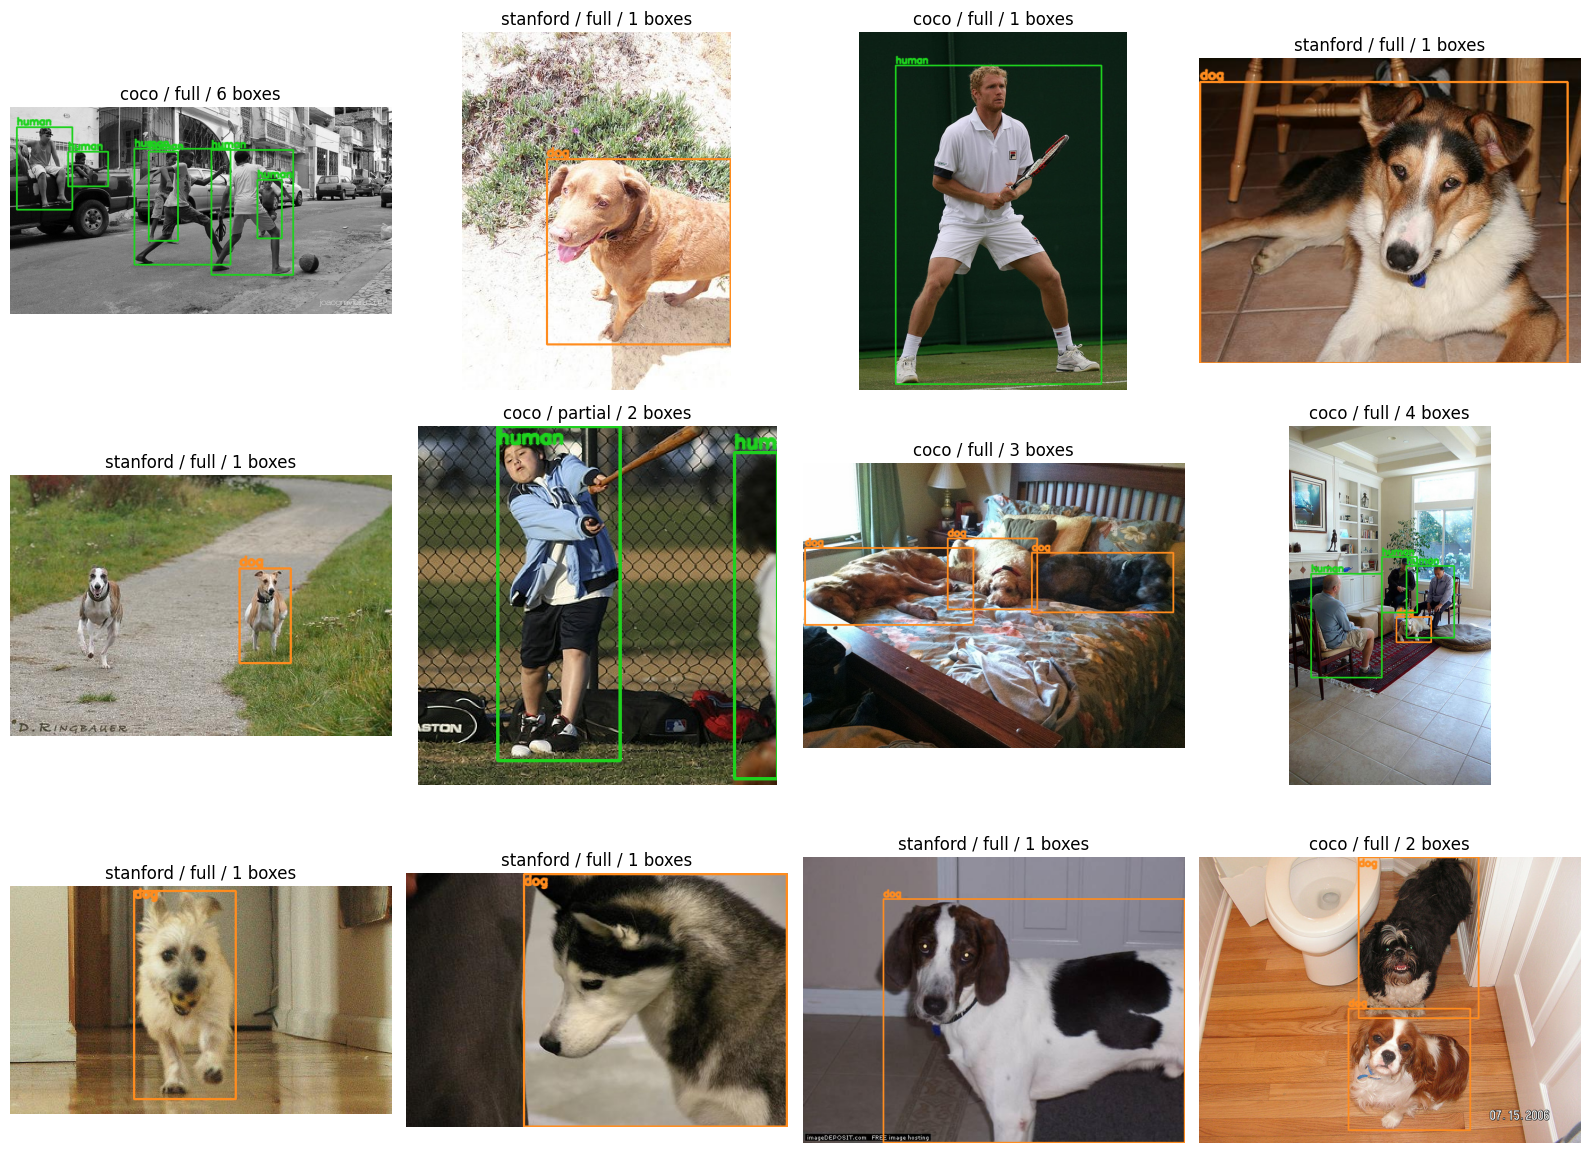

In [7]:
PREVIEW_ROWS = sample_preview_rows(DATASET_ROOT, split="train", count=12, seed=CONFIG["seed"])
figure, axes = plt.subplots(3, 4, figsize=(16, 12))
for axis, row in zip(axes.flat, PREVIEW_ROWS):
    axis.imshow(draw_labelled_image(DATASET_ROOT, row))
    axis.set_title(f"{row['source']} / {row['variant']} / {row['box_count']} boxes")
    axis.axis("off")
for axis in axes.flat[len(PREVIEW_ROWS):]:
    axis.axis("off")
plt.tight_layout()


## Training configuration

The model input is fixed at 320 because the deployed camera produces 320 x 320 frames. A pretrained YOLOv8n model is trained for at most 60 epochs with validation every epoch and early stopping. Batch 16 is a practical starting point for YOLOv8n at 320 on an M2 Pro with 16 GB unified memory; reduce it to 8 only if MPS reports memory pressure.

The main run uses mosaic early in training and disables it for the final ten epochs. The optional ablation repeats the same experiment without mosaic.


In [8]:
TRAIN_DEVICE = "mps" if torch.backends.mps.is_available() else "cuda" if torch.cuda.is_available() else "cpu"
MODEL_WEIGHTS = "yolov8n.pt"
DATA_YAML = Path(DATASET_METADATA["yaml_paths"]["combined"])
RUNS_ROOT = Path("/opt/homebrew/runs/quadrupedvision")
DATASET_IDENTITY = dataset_identity(DATASET_METADATA)
EXPERIMENT_NAME = f"yolov8n-320-v2-mosaic-{DATASET_IDENTITY['fingerprint'][:12]}"

MAIN_TRAIN_ARGS = training_arguments(
    data_yaml=DATA_YAML,
    project=RUNS_ROOT,
    name=EXPERIMENT_NAME,
    device=TRAIN_DEVICE,
    mosaic=1.0,
)
MAIN_RUN_BINDING = run_binding_path(MAIN_TRAIN_ARGS)
print("Training device:", TRAIN_DEVICE)
print(format_yolo_cli(
    MODEL_WEIGHTS,
    MAIN_TRAIN_ARGS,
    dataset_root=DATASET_ROOT,
    identity=DATASET_IDENTITY,
))


Training device: mps
(test ! -e /opt/homebrew/runs/quadrupedvision/yolov8n-320-v2-mosaic-20ecc1fa7875 || (echo 'Run already exists: /opt/homebrew/runs/quadrupedvision/yolov8n-320-v2-mosaic-20ecc1fa7875' >&2 && false)) && \
find /Users/romansannikov/Projects/quadrupedvision/dataset_v2/labels -type f -name '*.cache' -delete && \
/opt/homebrew/opt/python@3.11/bin/python3.11 -c 'from pathlib import Path; from quadruped_pipeline import prepare_run_binding; prepare_run_binding(Path('"'"'/opt/homebrew/runs/quadrupedvision/.run-bindings/yolov8n-320-v2-mosaic-20ecc1fa7875.json'"'"'), '"'"'yolov8n.pt'"'"', {'"'"'data'"'"': '"'"'/Users/romansannikov/Projects/quadrupedvision/dataset_v2.yaml'"'"', '"'"'epochs'"'"': 60, '"'"'imgsz'"'"': 320, '"'"'batch'"'"': 16, '"'"'patience'"'"': 15, '"'"'device'"'"': '"'"'mps'"'"', '"'"'workers'"'"': 0, '"'"'project'"'"': '"'"'/opt/homebrew/runs/quadrupedvision'"'"', '"'"'name'"'"': '"'"'yolov8n-320-v2-mosaic-20ecc1fa7875'"'"', '"'"'exist_ok'"'"': False, '"'"'pre

In [9]:
RUN_TRAINING = True
RESUME_CHECKPOINT = RUNS_ROOT / EXPERIMENT_NAME / "weights/last.pt"
# RUN_TRAINING = False
# RESUME_CHECKPOINT = None  # Set only to this experiment's explicit last.pt after an interruption.

if RUN_TRAINING:
    clear_ultralytics_label_caches(DATASET_ROOT)
    if RESUME_CHECKPOINT is not None:
        checkpoint = Path(RESUME_CHECKPOINT)
        verify_checkpoint_binding(
            checkpoint,
            MAIN_RUN_BINDING,
            MODEL_WEIGHTS,
            MAIN_TRAIN_ARGS,
            DATASET_IDENTITY,
            allow_pending_last=True,
        )
        TRAIN_RESULT = YOLO(str(checkpoint)).train(resume=True)
    else:
        run_directory = RUNS_ROOT / EXPERIMENT_NAME
        if run_directory.exists():
            raise FileExistsError(f"Run already exists: {run_directory}. Choose a new experiment name.")
        prepare_run_binding(
            MAIN_RUN_BINDING,
            MODEL_WEIGHTS,
            MAIN_TRAIN_ARGS,
            DATASET_IDENTITY,
        )
        TRAIN_RESULT = YOLO(MODEL_WEIGHTS).train(**MAIN_TRAIN_ARGS)
    finalize_run_binding(MAIN_RUN_BINDING)


New https://pypi.org/project/ultralytics/8.4.96 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.53 🚀 Python-3.11.13 torch-2.12.0 MPS (Apple M2 Pro)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/Users/romansannikov/Projects/quadrupedvision/dataset_v2.yaml, degrees=3.0, deterministic=True, device=mps, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=60, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.5, hsv_v=0.3, imgsz=320, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=/opt/homebrew/runs/quadrupedvision/yolov8n-320-

In [10]:
RUN_NO_MOSAIC_ABLATION = False
NO_MOSAIC_NAME = f"yolov8n-320-v2-no-mosaic-{DATASET_IDENTITY['fingerprint'][:12]}"
NO_MOSAIC_ARGS = training_arguments(
    data_yaml=DATA_YAML,
    project=RUNS_ROOT,
    name=NO_MOSAIC_NAME,
    device=TRAIN_DEVICE,
    mosaic=0.0,
)
NO_MOSAIC_BINDING = run_binding_path(NO_MOSAIC_ARGS)
print(format_yolo_cli(
    MODEL_WEIGHTS,
    NO_MOSAIC_ARGS,
    dataset_root=DATASET_ROOT,
    identity=DATASET_IDENTITY,
))

if RUN_NO_MOSAIC_ABLATION:
    clear_ultralytics_label_caches(DATASET_ROOT)
    run_directory = RUNS_ROOT / NO_MOSAIC_NAME
    if run_directory.exists():
        raise FileExistsError(f"Run already exists: {run_directory}. Choose a new experiment name.")
    prepare_run_binding(
        NO_MOSAIC_BINDING,
        MODEL_WEIGHTS,
        NO_MOSAIC_ARGS,
        DATASET_IDENTITY,
    )
    NO_MOSAIC_RESULT = YOLO(MODEL_WEIGHTS).train(**NO_MOSAIC_ARGS)
    finalize_run_binding(NO_MOSAIC_BINDING)


(test ! -e /opt/homebrew/runs/quadrupedvision/yolov8n-320-v2-no-mosaic-20ecc1fa7875 || (echo 'Run already exists: /opt/homebrew/runs/quadrupedvision/yolov8n-320-v2-no-mosaic-20ecc1fa7875' >&2 && false)) && \
find /Users/romansannikov/Projects/quadrupedvision/dataset_v2/labels -type f -name '*.cache' -delete && \
/opt/homebrew/opt/python@3.11/bin/python3.11 -c 'from pathlib import Path; from quadruped_pipeline import prepare_run_binding; prepare_run_binding(Path('"'"'/opt/homebrew/runs/quadrupedvision/.run-bindings/yolov8n-320-v2-no-mosaic-20ecc1fa7875.json'"'"'), '"'"'yolov8n.pt'"'"', {'"'"'data'"'"': '"'"'/Users/romansannikov/Projects/quadrupedvision/dataset_v2.yaml'"'"', '"'"'epochs'"'"': 60, '"'"'imgsz'"'"': 320, '"'"'batch'"'"': 16, '"'"'patience'"'"': 15, '"'"'device'"'"': '"'"'mps'"'"', '"'"'workers'"'"': 0, '"'"'project'"'"': '"'"'/opt/homebrew/runs/quadrupedvision'"'"', '"'"'name'"'"': '"'"'yolov8n-320-v2-no-mosaic-20ecc1fa7875'"'"', '"'"'exist_ok'"'"': False, '"'"'pretrained'"

## Validation and untouched test evaluation

The checkpoint path is explicit. Combined, COCO-only, and Stanford-only metrics are kept separate so source-specific behavior cannot be hidden by an aggregate score. The operating confidence is chosen from validation F1 and then applied unchanged to negative test images. Test summaries contain AP only: precision, recall, and F1 from Ultralytics would otherwise be optimized on the test confidence curve rather than measured at the validation-selected operating point.


In [11]:
CHECKPOINT = RUNS_ROOT / EXPERIMENT_NAME / "weights/best.pt"
EVALUATION_ROOT = Path("/opt/homebrew/runs/quadrupedvision-evaluation")
EVALUATION_YAMLS = {
    scope: Path(path)
    for scope, path in DATASET_METADATA["yaml_paths"].items()
}
RUN_VALIDATION = False

VALIDATION_METRICS = {}
if RUN_VALIDATION:
    if not CHECKPOINT.exists():
        raise FileNotFoundError(CHECKPOINT)
    verify_checkpoint_binding(
        CHECKPOINT,
        MAIN_RUN_BINDING,
        MODEL_WEIGHTS,
        MAIN_TRAIN_ARGS,
        DATASET_IDENTITY,
    )
    validation_directories = [
        EVALUATION_ROOT / f"{EXPERIMENT_NAME}-val-{scope}"
        for scope in EVALUATION_YAMLS
    ]
    existing = [path for path in validation_directories if path.exists()]
    if existing:
        raise FileExistsError(f"Validation output already exists: {existing}")
    EVALUATION_MODEL = YOLO(str(CHECKPOINT))
    for scope, yaml_path in EVALUATION_YAMLS.items():
        clear_ultralytics_label_caches(DATASET_ROOT)
        metrics = EVALUATION_MODEL.val(
            data=str(yaml_path),
            split="val",
            imgsz=CONFIG["image_size"],
            batch=16,
            device=TRAIN_DEVICE,
            rect=False,
            project=str(EVALUATION_ROOT),
            name=f"{EXPERIMENT_NAME}-val-{scope}",
            exist_ok=False,
            plots=True,
        )
        VALIDATION_METRICS[scope] = metrics
        print(scope, summarize_metrics(metrics))
else:
    print("Set RUN_VALIDATION=True after training. Expected checkpoint:", CHECKPOINT)


Set RUN_VALIDATION=True after training. Expected checkpoint: /opt/homebrew/runs/quadrupedvision/yolov8n-320-v2-mosaic-20ecc1fa7875/weights/best.pt


In [12]:
RUN_TEST_EVALUATION = False
TEST_METRICS = {}
if RUN_TEST_EVALUATION:
    if not VALIDATION_METRICS:
        raise RuntimeError("Run validation first so the confidence threshold is selected without test data.")
    OPERATING_CONFIDENCE = best_f1_confidence(VALIDATION_METRICS["combined"])
    print("Validation-selected confidence:", OPERATING_CONFIDENCE)
    test_directories = [
        EVALUATION_ROOT / f"{EXPERIMENT_NAME}-test-{scope}"
        for scope in EVALUATION_YAMLS
    ]
    existing = [path for path in test_directories if path.exists()]
    if existing:
        raise FileExistsError(f"Test output already exists: {existing}")
    for scope, yaml_path in EVALUATION_YAMLS.items():
        clear_ultralytics_label_caches(DATASET_ROOT)
        metrics = validate_without_metric_logging(
            EVALUATION_MODEL,
            data=str(yaml_path),
            split="test",
            imgsz=CONFIG["image_size"],
            batch=16,
            device=TRAIN_DEVICE,
            rect=False,
            project=str(EVALUATION_ROOT),
            name=f"{EXPERIMENT_NAME}-test-{scope}",
            exist_ok=False,
            plots=False,
        )
        TEST_METRICS[scope] = metrics
        print(scope, summarize_ap_metrics(metrics))

    NEGATIVE_TEST_REPORT = negative_false_positive_rate(
        model=EVALUATION_MODEL,
        dataset_root=DATASET_ROOT,
        split="test",
        confidence=OPERATING_CONFIDENCE,
        device=TRAIN_DEVICE,
        image_size=CONFIG["image_size"],
        batch=16,
    )
    print("Negative test set:", NEGATIVE_TEST_REPORT)


## Pretrained COCO baseline

The original YOLOv8n predicts COCO class 0 for person and class 16 for dog, while this dataset uses class 0 for human and class 1 for dog. The evaluator remaps those predictions before computing AP. This is a true no-fine-tuning baseline on the same validation and test images.


In [13]:
RUN_PRETRAINED_BASELINE = False
BASELINE_PLOT_DIR = EVALUATION_ROOT / f"pretrained-baseline-val-{DATASET_IDENTITY['fingerprint'][:12]}"

if RUN_PRETRAINED_BASELINE:
    BASELINE_VAL = evaluate_coco_pretrained_baseline(
        model_path=MODEL_WEIGHTS,
        dataset_root=DATASET_ROOT,
        list_path=DATASET_ROOT / "val.txt",
        device=TRAIN_DEVICE,
        image_size=CONFIG["image_size"],
        batch=16,
        plot_dir=BASELINE_PLOT_DIR,
    )
    BASELINE_TEST = evaluate_coco_pretrained_baseline(
        model_path=MODEL_WEIGHTS,
        dataset_root=DATASET_ROOT,
        list_path=DATASET_ROOT / "test.txt",
        device=TRAIN_DEVICE,
        image_size=CONFIG["image_size"],
        batch=16,
        plot_dir=None,
    )
    print("Baseline validation:", summarize_metrics(BASELINE_VAL))
    print("Baseline test (AP only):", summarize_ap_metrics(BASELINE_TEST))


## Batch-one benchmark and Raspberry Pi export

A benchmark run here measures the current Mac, not the Raspberry Pi. The helper center-crops a public test image to a square, resizes it once to a 320 x 320 in-memory camera-format frame, and excludes file decoding from the timed loop. For the thesis, export the model and run the same batch-one benchmark on the Pi. Since the live camera frame is already 320 x 320 and 320 is divisible by the model stride, inference does not require aspect-ratio padding.


In [14]:
RUN_BATCH_ONE_BENCHMARK = False

if RUN_BATCH_ONE_BENCHMARK:
    verify_checkpoint_binding(
        CHECKPOINT, MAIN_RUN_BINDING, MODEL_WEIGHTS, MAIN_TRAIN_ARGS, DATASET_IDENTITY
    )
    benchmark_image = resolve_image_list(DATASET_ROOT, DATASET_ROOT / "test.txt")[0]
    benchmark_model = YOLO(str(CHECKPOINT))
    MAC_BENCHMARK = benchmark_batch_one(
        model=benchmark_model,
        image_path=benchmark_image,
        device=TRAIN_DEVICE,
        image_size=CONFIG["image_size"],
        warmup=5,
        iterations=30,
    )
    print(MAC_BENCHMARK)


In [15]:
RUN_NCNN_EXPORT = False

if RUN_NCNN_EXPORT:
    verify_checkpoint_binding(
        CHECKPOINT, MAIN_RUN_BINDING, MODEL_WEIGHTS, MAIN_TRAIN_ARGS, DATASET_IDENTITY
    )
    export_model = YOLO(str(CHECKPOINT))
    NCNN_EXPORT = export_model.export(
        format="ncnn",
        imgsz=CONFIG["image_size"],
        device="cpu",
        half=False,
    )
    print("NCNN export:", NCNN_EXPORT)


## Required run order

1. Run source loading and Stanford person screening.
2. Build `dataset_v2` with `REBUILD_DATASET=True` the first time the configuration changes.
3. Run the full audit and inspect the rendered samples before training.
4. Run the printed CLI command, or set `RUN_TRAINING=True`.
5. Evaluate the explicit `best.pt` on validation and test exactly once for the final thesis result.
6. Compare with the pretrained baseline and optional no-mosaic ablation.
7. Export and benchmark on the Raspberry Pi before making an on-device real-time claim.

The public datasets still cannot reproduce the exact 17 cm camera viewpoint. Results should therefore be described as public-dataset generalization, not direct validation of the physical robot viewpoint.
